<a href="https://colab.research.google.com/github/cpt0/Project-2/blob/main/Project2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd

DATA_PATH = '/content/drive/MyDrive/DATA 201/Datasets/dataset_Facebook.csv'   # change this if needed
fb = pd.read_csv(DATA_PATH, sep = ';')

print(fb.shape)
print(fb.head())

Mounted at /content/drive
(500, 19)
   Page total likes    Type  Category  Post Month  Post Weekday  Post Hour  \
0            139441   Photo         2          12             4          3   
1            139441  Status         2          12             3         10   
2            139441   Photo         3          12             3          3   
3            139441   Photo         2          12             2         10   
4            139441   Photo         2          12             2          3   

   Paid  Lifetime Post Total Reach  Lifetime Post Total Impressions  \
0   0.0                       2752                             5091   
1   0.0                      10460                            19057   
2   0.0                       2413                             4373   
3   1.0                      50128                            87991   
4   0.0                       7244                            13594   

   Lifetime Engaged Users  Lifetime Post Consumers  \
0             

In [3]:
fb.isna().sum()

,0
Page total likes,0
Type,0
Category,0
Post Month,0
Post Weekday,0
Post Hour,0
Paid,1
Lifetime Post Total Reach,0
Lifetime Post Total Impressions,0
Lifetime Engaged Users,0


In [4]:
cleanfb = fb.dropna()
print(cleanfb.shape)

(495, 19)


In [5]:
fb2 = pd.get_dummies(cleanfb, columns=['Type','Paid','Category','Post Month','Post Weekday','Post Hour'], drop_first=False, dtype=int)
print(fb2)


     Page total likes  Lifetime Post Total Reach  \
0              139441                       2752   
1              139441                      10460   
2              139441                       2413   
3              139441                      50128   
4              139441                       7244   
..                ...                        ...   
494             85093                       5400   
495             85093                       4684   
496             81370                       3480   
497             81370                       3778   
498             81370                       4156   

     Lifetime Post Total Impressions  Lifetime Engaged Users  \
0                               5091                     178   
1                              19057                    1457   
2                               4373                     177   
3                              87991                    2211   
4                              13594                   

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree, export_text
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

In [7]:
X = fb2.drop(columns=['Total Interactions'])
y = fb2['Total Interactions']
# Hold out 30% of patients for testing. stratify keeps the class mix similar in both parts.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=50)


print(X_train.shape, X_test.shape)

#you can check your sets (X_train, X_test,...)
X_train.head()

(346, 62) (149, 62)


,Page total likes,Lifetime Post Total Reach,Lifetime Post Total Impressions,Lifetime Engaged Users,Lifetime Post Consumers,Lifetime Post Consumptions,Lifetime Post Impressions by people who have liked your Page,Lifetime Post reach by people who like your Page,Lifetime People who have liked your Page and engaged with your post,comment,...,Post Hour_13,Post Hour_14,Post Hour_15,Post Hour_16,Post Hour_17,Post Hour_18,Post Hour_19,Post Hour_20,Post Hour_22,Post Hour_23
3,139441,50128,87991,2211,790,1119,61027,32048,1386,58,...,0,0,0,0,0,0,0,0,0,0
205,132201,3254,5644,371,344,513,5069,2846,283,0,...,0,0,0,0,0,0,0,0,0,0
35,138895,4512,7808,423,284,431,5183,2954,316,6,...,0,0,0,0,0,0,0,0,0,0
334,119198,10152,17099,1636,1599,2755,15382,8980,1613,2,...,0,0,0,0,0,0,0,0,0,0
55,138329,16416,31950,459,411,539,21436,9568,363,2,...,0,0,0,0,0,0,0,0,0,0


In [8]:
zuckertree = DecisionTreeRegressor(random_state=50, max_depth=None)
zuckertree.fit(X_train, y_train)

train_pred = zuckertree.predict(X_train)
test_pred = zuckertree.predict(X_test)

print('Train RMSE:', np.sqrt(mean_squared_error(y_train, train_pred)))
print('Test RMSE:', np.sqrt(mean_squared_error(y_test, test_pred)))

Train RMSE: 0.0
Test RMSE: 53.61182880595907


In [9]:
# Why Train RMSE is 0.0 for Decision Trees:
# When max_depth=None, the tree splits until every training sample is perfectly isolated.
# This leads to perfect memorization (overfitting), resulting in 0 Train RMSE but higher Test RMSE.

from sklearn.ensemble import RandomForestRegressor

faceforest = RandomForestRegressor(random_state=50, n_estimators=100, n_jobs=1)
faceforest.fit(X_train, y_train)

train2_pred = faceforest.predict(X_train)
test2_pred = faceforest.predict(X_test)

print('Train RMSE:', np.sqrt(mean_squared_error(y_train, train2_pred)))
print('Test RMSE:', np.sqrt(mean_squared_error(y_test, test2_pred)))

Train RMSE: 90.283168975668
Test RMSE: 78.80250576024825


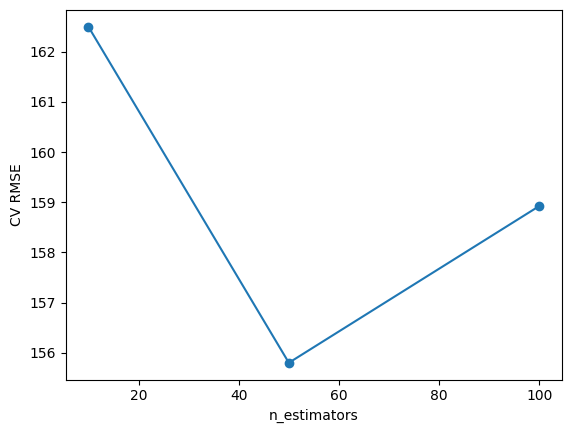

In [10]:
tree_counts = [10, 50, 100]
cv_rmse = []
for n in tree_counts:
  m = RandomForestRegressor(n_estimators=n, max_depth=None,random_state=50)
  scores = cross_val_score(m, X_train, y_train, cv=5, scoring='neg_root_mean_squared_error')
  cv_rmse.append(-scores.mean())

plt.plot(tree_counts, cv_rmse, marker='o')
plt.xlabel('n_estimators')
plt.ylabel('CV RMSE')
plt.show()

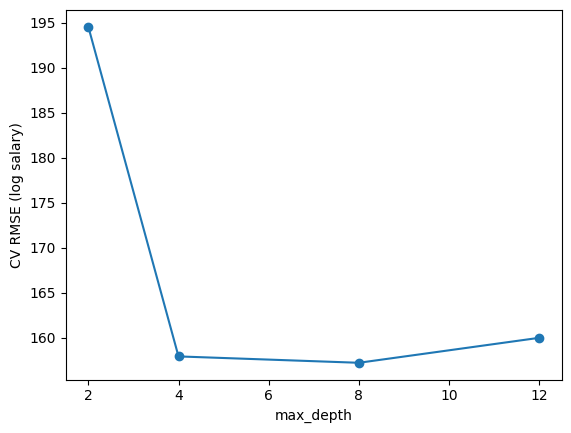

In [11]:
depths = [2,4,8,12]
cv_rmse = []
for d in depths:
    h = RandomForestRegressor(max_depth=d, n_estimators=100, random_state=50)
    scores = cross_val_score(h, X_train, y_train, cv=5, scoring='neg_root_mean_squared_error')
    cv_rmse.append(-scores.mean())

plt.plot(depths, cv_rmse, marker='o')
plt.xlabel('max_depth'); plt.ylabel('CV RMSE (log salary)'); plt.show()

In [12]:
metaforest = RandomForestRegressor(random_state=50, n_estimators=100, max_depth=8, n_jobs=1)
metaforest.fit(X_train, y_train)

test3_pred = metaforest.predict(X_test)
print('Test RMSE:', np.sqrt(mean_squared_error(y_test, test3_pred)))

Test RMSE: 79.22679252509192


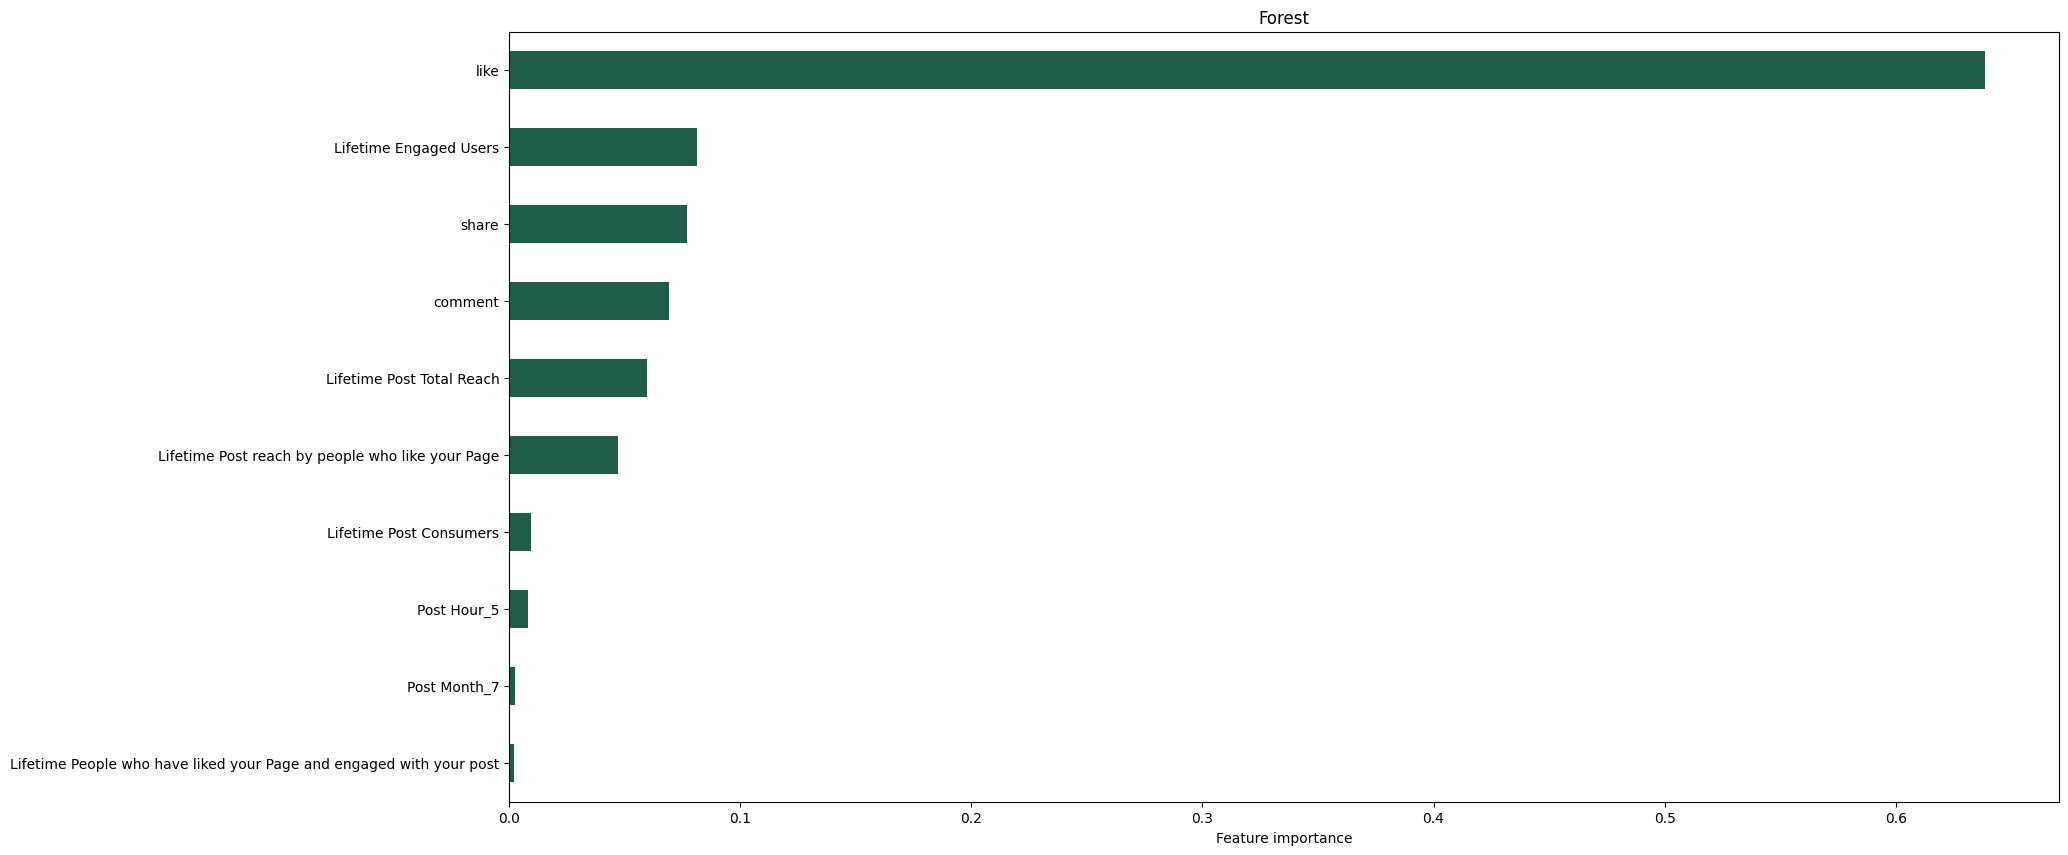

In [19]:
imp = pd.Series(metaforest.feature_importances_, index=X.columns).sort_values()

imp[imp > 0].tail(10).plot(kind='barh', figsize=(20, 10), color='#1F5C4A')
plt.xlabel('Feature importance'); plt.title('Forest'); plt.show()

#.tail allows us to only show 10 features.